# accim: a Python library for adaptive setpoint temperatures in building performance simulations

This Jupyter Notebook contains the code for the case study (Section 3 Results) of the research paper *accim: a Python library for adaptive setpoint temperatures in building performance simulations* (Journal of Building Performance Simulation, 2025, https://doi.org/10.1080/19401493.2025.2472305). It has been developed to ease the reproducibility of the paper, and the replicability with other IDF and EPW files or other arguments.

The notebook was written for accim 0.7.3 (hence the name of its folder) and has been updated to run with the current version of accim and EnergyPlus 25.1: the IDF has been updated from EnergyPlus 23.1 to 25.1. Therefore, the results may differ slightly from those in the paper.

## 3. Results

In this case study, the aim is the analysis of energy demand resulting from the use of adaptive setpoint temperatures based on a local adaptive comfort model for office buildings in India, named IMAC-C, and the comparison with ASHRAE 55 adaptive model and static setpoints from the Indian Building Code, in different operation modes. In this study, 2 different locations, a present and a future scenario, are considered, resulting in 4 different EPW files.

The building energy model used is the 2018 IECC DOE Commercial Reference Building Prototype Small Office. It has 6 thermal zones: a thermal zone in the centre of the building (CORE_ZN), surrounded by 4 thermal zones (PERIMETER_ZN_1 to 4), all of them air-conditioned and located on the ground floor, and a non-air-conditioned attic (Figure 3). In the IDF, these zones are named Block1:CoreXZN, Block1:PerimeterXZNX1 to 4 and Attic:Attic. Since this is a well-known model, no further details are provided, however these are included in the folder with the IDF and EPW files, in an XLS file provided by DOE and named “PNNL_Scorecard_Prototypes_Office_Small.xls” as well as available online in https://www.energycodes.gov/prototype-building-models#Commercial.


The available EPW files in this path are:

In [1]:
from os import listdir
input_files = [i for i in listdir()]
input_epws = [i for i in input_files if i.endswith('.epw')]
print(*input_epws, sep='\n')

Current_Ahmedabad-hour.epw
Current_Shimla-hour.epw
RCP852100_Ahmedabad-hour.epw
RCP852100_Shimla-hour.epw


and the available IDF file or files are:

In [2]:
input_idfs = [i for i in input_files if i.endswith('.idf')]
print(*input_idfs, sep='\n')

SmallOffice.idf


At this point, the methodology explained in the research paper can be applied. It will be composed of the following sections and subsections:
- __Data pre-processing__
    - __EPW files preparation__
    - __ACCIS implementation__
- __Running simulations__
- __Data analysis__
    - __Tables__
    - __Data visualization__

## 3.1 Data pre-processing

At this stage, input files need to be prepared for simulation.

### 3.1.1.	EPW files preparation

First, EPWs will be formatted to a suitable name pattern for later simulation. To do so, the user can instantiate the class `rename_epw_files`. The city names are entered with the argument `rename_city_dict`, and their country with `country_to_city_dict`, so that accim does not need to look them up from the coordinates of the EPW files (which would need an internet connection). After instantiating the class, the user will need to interact with accim at the python console or CMD terminal: in this case, by hitting enter twice, since no amendments or exclusions are needed. `confirm_renaming` has been set to ``True`` to skip the confirmation, and `confirm_deletion` to ``False`` to avoid the deletion of the original files, since these are needed to re-run the Jupyter Notebook.

In [3]:
from accim.data.preprocessing import rename_epw_files
rename_epw_files(
    rename_city_dict={
        'Ahmedabad': 'Ahmedabad',
        'Shimla': 'Shimla'
    },
    country_to_city_dict={
        'India': ['Ahmedabad', 'Shimla']
    },
    confirm_deletion=False,
    confirm_renaming=True
)

Since no match has been found between RCP or SSP scenario Year and EPW file name, Present year has been assigned to the following EPW files:
Current_Ahmedabad-hour.epw
Current_Shimla-hour.epw
The geolocation process has taken: 0.06 seconds (0.01 s/EPW)

The previous and new names of the EPW files and their unique IDs are:
ID: 0 / Current_Ahmedabad-hour / India_Ahmedabad_Present
ID: 1 / Current_Shimla-hour / India_Shimla_Present
ID: 2 / RCP852100_Ahmedabad-hour / India_Ahmedabad_RCP85-2100
ID: 3 / RCP852100_Shimla-hour / India_Shimla_RCP85-2100

If any of the city or subcountry names needs some amendment (if you are not happy with any of the available options, you can exclude it from renaming at the next stage), please enter the EPW IDs separated by space; otherwise, hit enter to omit:

The final list of previous and new names of the EPW files and their unique IDs is:
ID: 0 / Current_Ahmedabad-hour / India_Ahmedabad_Present
ID: 1 / Current_Shimla-hour / India_Shimla_Present
ID: 2 / RCP8

The tool renamed correctly all EPW files at the first instance and no amendments were required. The new EPWs are:

In [4]:
output_epws = [i for i in listdir() if i.endswith('.epw') if i not in input_epws]
print(*output_epws, sep='\n')

India_Ahmedabad_Present.epw
India_Ahmedabad_RCP85-2100.epw
India_Shimla_Present.epw
India_Shimla_RCP85-2100.epw


Now, the old EPWs need to be moved to a different folder to save them as a backup.

In [5]:
import shutil
for i in input_epws:
    shutil.move(i, f'backup/{i}')

### 3.1.2.	ACCIS implementation

First, let's apply 24/7 (always on) schedules to occupancy, so that we have the HVAC system on all the hours of the year. ``set_occupancy_to_always_path`` overwrites the IDF, so we first keep a copy of the original in the folder ``backup``, to restore it at the end of the notebook.

In [6]:
from accim.utils import set_occupancy_to_always_path
shutil.copy('SmallOffice.idf', 'backup/SmallOffice.idf')
set_occupancy_to_always_path(idfpath='SmallOffice.idf')

On 24/7 Schedule:Compact object was already in the model.
People Block1:PerimeterXZNX4 Number of People Schedule Name has been set to always occupied.
People Block1:CoreXZN Number of People Schedule Name has been set to always occupied.
People Block1:PerimeterXZNX2 Number of People Schedule Name has been set to always occupied.
People Block1:PerimeterXZNX1 Number of People Schedule Name has been set to always occupied.
People Block1:PerimeterXZNX3 Number of People Schedule Name has been set to always occupied.


The next step is applying the adaptive setpoint temperatures. To do so, the class ``AddAccis`` needs to be used. Again, the recommended process, suitable for users with no programming background, is:
- open a CMD terminal pointing at the path where the EPW files to be renamed are located
- execute Python by entering ``py`` or ``python``
- import the package by entering ``from accim.sim import accis``
- call the function by entering ``accis.AddAccis()``
- enter the required information on CMD terminal (related to the arguments that have not been specified)

In this case study, all arguments are specified as shown below:
-	``script_type`` is ``'vrf_mm'``, since this option adds a generic VRF system for each zone, and the input IDF was a generic model exported from DesignBuilder without any HVAC system at all.
-	``'temperature difference'`` in argument ``supply_air_temp_input_method`` specifies the type of supply air temperature input method for the VRF systems. This is due to the fact that, running simulations in hot weather with high cooling setpoint temperatures might result in little cooling needs, sometimes too little to be used with a generic cooling supply air temperature of 14°C.
-	``keep_existing_outputs`` is set to ``False`` in order to not to generate unnecessary results.
-	``output_type`` is set to ``'standard'``, in order to provide typical results. Other options might be used when a large amount of simulations is carried out and file size needs to be reduced, or when very specific results need to be exported for the testing of the tool.
-	``output_frequencies`` is set only to ``'hourly'``, since aggregation into other frequencies will be performed later in data analysis. If additional frequencies were required, these could be added to the list (i.e. ``['hourly', 'daily', 'monthly', 'runperiod']``)
- ``make_outputs_dataframe`` is set to False, since the generation of the pandas DataFrame containing Output:Variable objects for output customisation is not needed.
-	``energyplus_version`` is set to ``'25.1'``, since that is the version of SmallOffice.idf.
-	``setpoint_type`` is set to ``'temperature'``, so that the operation of the HVAC system is based on the operative temperature. If ``'pmv'`` was used, setpoints would be ±0.5.
-	``comfort_standard`` requested values are ``2`` and ``7``, since these are the numbers respectively for ASHRAE 55 and IMAC-C in NV mode.
-	``category`` is set only to ``80``, so that the offset of setpoint temperatures from neutral temperature covers an 80% acceptability.
-	``comfort_mode`` requested values are ``0`` and ``3``, since these are respectively for static and adaptive setpoints, and in this study, adaptive setpoints from IMAC-C and static setpoints from Indian Building Code are to be compared.
- ``setpoint_accuracy`` is set to 100, since HVAC units thermostats are considered to be accurate up to the second decimal.
- ``cooling_season_start`` and ``cooling_season_end`` are set to dates 01/05 and 01/10 respectively, however these are not necessary in this case.
-	``hvac_mode`` requested values are ``0``, ``1`` and ``2``, since those are respectively for AC, NV and MM operation modes. In this case study, may be interesting to evaluate the energy performance of MM against AC. Also, may be interesting to see the difference in comfort hours between NV and MM mode.
-	``ventilation_control``, ``ventilation_setpoint_offset``, ``min_outdoor_temp_offset`` and ``max_wind_speed`` are arguments to control the operation of MM. In this case, the windows are opened when operative temperature exceeds the neutral temperature (``ventilation_control`` is 0) with no offset (``ventilation_setpoint_offset`` is 0), and no restrictions in terms of minimum outdoor temperature and maximum wind speed are set (``min_outdoor_temp_offset`` and ``max_wind_speed`` are 50).
-	``setpoint_tolerance_step``, ``setpoint_tolerance_start`` and ``setpoint_tolerance_end`` are mainly used to apply some tolerances to make sure there are no hours that fall outside the comfort zone by a little extent. These can also be used to generate an array of setpoint temperatures. In this case, it applies a ±0.1°C offset to heating and cooling setpoints.

In [7]:
from accim.sim import accis
accis.AddAccis(
    script_type='vrf_mm',
    supply_air_temp_input_method='temperature difference',
    keep_existing_outputs=False,
    output_type='standard',
    output_frequencies=['hourly'],
    make_outputs_dataframe=False,
    energyplus_version='25.1',
    setpoint_type='temperature',
    comfort_standard=[2, 7],
    category=[80],
    comfort_mode=[0, 3],
    setpoint_accuracy=100,
    cooling_season_start='01/05',
    cooling_season_end='01/10',
    hvac_mode=[0, 1, 2],
    ventilation_control=[0],
    ventilation_setpoint_offset=[0],
    min_outdoor_temp_offset=[50],
    max_wind_speed=[50],
    setpoint_tolerance_step=0.1,
    setpoint_tolerance_start=0.1,
    setpoint_tolerance_end=0.1,
    confirm=True,
)


--------------------------------------------------------
Adaptive-Comfort-Control-Implemented Model (ACCIM) v1.1.0
--------------------------------------------------------

This tool allows to apply adaptive setpoint temperatures. 
For further information, please read the documentation: 
https://accim.readthedocs.io/en/master/
For a visual understanding of the tool, please visit the following jupyter notebooks:
-    Using AddAccis() to apply adaptive setpoint temperatures
https://accim.readthedocs.io/en/master/jupyter_notebooks/addAccis/using_addAccis.html
-    Using rename_epw_files() to rename the EPWs for proper data analysis after simulation
https://accim.readthedocs.io/en/master/jupyter_notebooks/rename_epw_files/using_rename_epw_files.html
-    Using run_ep() to directly run simulations with EnergyPlus
https://accim.readthedocs.io/en/master/jupyter_notebooks/runEp/using_runEp.html
-    Using the class Table() for data analysis
https://accim.readthedocs.io/en/master/jupyter_noteb

tmp\ipykernel_32720\1344461910.py:2: UserWarning: The occupied zones ['Block1:CoreXZN'] of the model SmallOffice have no exterior windows, doors or glass doors with AirflowNetwork openings, so in mixed mode they are only air-conditioned: accim cannot open their windows.
  accis.AddAccis(


Air distribution effectiveness (always 1) Schedule has been added
VRF Heating Cooling (Northern Hemisphere) Schedule has been added
DefaultFanEffRatioCurve Curve:Cubic Object has been added
VRFTUCoolCapFT Curve:Cubic Object has been added
VRFTUHeatCapFT Curve:Cubic Object has been added
VRFCoolCapFTBoundary Curve:Cubic Object has been added
VRFCoolEIRFTBoundary Curve:Cubic Object has been added
CoolingEIRLowPLR Curve:Cubic Object has been added
VRFHeatCapFTBoundary Curve:Cubic Object has been added
VRFHeatEIRFTBoundary Curve:Cubic Object has been added
HeatingEIRLowPLR Curve:Cubic Object has been added
DefaultFanPowerRatioCurve Curve:Exponent Object has been added
DXHtgCoilDefrostEIRFT Curve:Biquadratic Object has been added
VRFCoolCapFT Curve:Biquadratic Object has been added
VRFCoolCapFTHi Curve:Biquadratic Object has been added
VRFCoolEIRFT Curve:Biquadratic Object has been added
VRFCoolEIRFTHi Curve:Biquadratic Object has been added
VRFHeatCapFT Curve:Biquadratic Object has been ad

AHST_Sch_Block1_PerimeterXZNX1 Schedule has been added
ACST_Sch_Block1_PerimeterXZNX1 Schedule has been added
AHST_Sch_Block1_PerimeterXZNX3 Schedule has been added
ACST_Sch_Block1_PerimeterXZNX3 Schedule has been added
Added - SetComfTemp Program
Added - CountHours_Block1_PerimeterXZNX4 Program
Added - CountHours_Block1_CoreXZN Program
Added - CountHours_Block1_PerimeterXZNX2 Program
Added - CountHours_Block1_PerimeterXZNX1 Program
Added - CountHours_Block1_PerimeterXZNX3 Program
Added - SetAppLimits Program
Added - ApplyCAT Program
Added - SetAST_Master Program
Added - SetAST_CS0_0 Program
Added - SetAST_CS1_0 Program
Added - SetAST_CS1_1 Program
Added - SetAST_CS2_0 Program
Added - SetAST_CS2_1 Program
Added - SetAST_CS3_0 Program
Added - SetAST_CS3_1 Program
Added - SetAST_CS4_0 Program
Added - SetAST_CS5_0 Program
Added - SetAST_CS6_0 Program
Added - SetAST_CS6_1 Program
Added - SetAST_CS7_0 Program
Added - SetAST_CS7_1 Program
Added - SetAST_CS8_0 Program
Added - SetAST_CS8_1 Pro

Added - SetAST_CS19_1 Program
Added - SetAST_CS20_0 Program
Added - SetAST_CS20_1 Program
Added - SetAST_CS21_0 Program
Added - SetAST_CS22_0 Program
Added - SetAST_CS99_0 Program
Added - SetAST Program
Added - SetASTnoTol Program
Added - InitASTvariables Program
Added - CountHoursNoApp_Block1_PerimeterXZNX4 Program
Added - SetGeoVarBlock1_PerimeterXZNX4 Program
Added - CountHoursNoApp_Block1_CoreXZN Program
Added - SetGeoVarBlock1_CoreXZN Program
Added - CountHoursNoApp_Block1_PerimeterXZNX2 Program
Added - SetGeoVarBlock1_PerimeterXZNX2 Program
Added - CountHoursNoApp_Block1_PerimeterXZNX1 Program
Added - SetGeoVarBlock1_PerimeterXZNX1 Program
Added - CountHoursNoApp_Block1_PerimeterXZNX3 Program
Added - SetGeoVarBlock1_PerimeterXZNX3 Program
Added - SetInputData_Block1_PerimeterXZNX4 Program
Added - SetInputData_Block1_CoreXZN Program
Added - SetInputData_Block1_PerimeterXZNX2 Program
Added - SetInputData_Block1_PerimeterXZNX1 Program
Added - SetInputData_Block1_PerimeterXZNX3 Progr

Added - SetMyVOF_Block1_PerimeterXZNX3_Wall_3_0_0_0_0_7_Door Program
Added - SetWindowOperation_Block1_PerimeterXZNX3_Wall_3_0_0_0_0_7_Door Program
Added - SetMyVOF_Block1_PerimeterXZNX3_Wall_3_0_0_1_0_6_Door Program
Added - SetWindowOperation_Block1_PerimeterXZNX3_Wall_3_0_0_1_0_6_Door Program
Added - SetMyVOF_Block1_PerimeterXZNX3_Wall_3_0_0_2_0_5_Win Program
Added - SetWindowOperation_Block1_PerimeterXZNX3_Wall_3_0_0_2_0_5_Win Program
Added - SetMyVOF_Block1_PerimeterXZNX3_Wall_3_0_0_3_0_4_Win Program
Added - SetWindowOperation_Block1_PerimeterXZNX3_Wall_3_0_0_3_0_4_Win Program
Added - SetMyVOF_Block1_PerimeterXZNX3_Wall_3_0_0_4_0_3_Win Program
Added - SetWindowOperation_Block1_PerimeterXZNX3_Wall_3_0_0_4_0_3_Win Program
Added - SetMyVOF_Block1_PerimeterXZNX3_Wall_3_0_0_5_0_2_Win Program
Added - SetWindowOperation_Block1_PerimeterXZNX3_Wall_3_0_0_5_0_2_Win Program
Added - SetMyVOF_Block1_PerimeterXZNX3_Wall_3_0_0_6_0_1_Win Program
Added - SetWindowOperation_Block1_PerimeterXZNX3_Wal

Added - Zone Floor Area_Block1_PerimeterXZNX2 Output Variable
Added - Zone Floor Area_Block1_PerimeterXZNX1 Output Variable
Added - Zone Floor Area_Block1_PerimeterXZNX3 Output Variable
Added - Zone Air Volume_Block1_PerimeterXZNX4 Output Variable
Added - Zone Air Volume_Block1_CoreXZN Output Variable
Added - Zone Air Volume_Block1_PerimeterXZNX2 Output Variable
Added - Zone Air Volume_Block1_PerimeterXZNX1 Output Variable
Added - Zone Air Volume_Block1_PerimeterXZNX3 Output Variable
Added - People Occupant Count_Block1_PerimeterXZNX4 Output Variable
Added - People Occupant Count_Block1_CoreXZN Output Variable
Added - People Occupant Count_Block1_PerimeterXZNX2 Output Variable
Added - People Occupant Count_Block1_PerimeterXZNX1 Output Variable
Added - People Occupant Count_Block1_PerimeterXZNX3 Output Variable
Added - Ventilation Hours_Block1_PerimeterXZNX4 Output Variable
Added - Ventilation Hours_Block1_CoreXZN Output Variable
Added - Ventilation Hours_Block1_PerimeterXZNX2 Output Va

Global variables objects have been added
Internal variables objects have been added
Added - RMOT Sensor
Added - PMOT Sensor
Added - Occ_count_Block1_PerimeterXZNX4 Sensor
Added - Occ_count_Block1_CoreXZN Sensor
Added - Occ_count_Block1_PerimeterXZNX2 Sensor
Added - Occ_count_Block1_PerimeterXZNX1 Sensor
Added - Occ_count_Block1_PerimeterXZNX3 Sensor
Added - Block1_PerimeterXZNX4_OpT Sensor
Added - Block1_PerimeterXZNX4_WindSpeed Sensor
Added - Block1_PerimeterXZNX4_OutT Sensor
Added - Block1_CoreXZN_OpT Sensor
Added - Block1_CoreXZN_WindSpeed Sensor
Added - Block1_CoreXZN_OutT Sensor
Added - Block1_PerimeterXZNX2_OpT Sensor
Added - Block1_PerimeterXZNX2_WindSpeed Sensor
Added - Block1_PerimeterXZNX2_OutT Sensor
Added - Block1_PerimeterXZNX1_OpT Sensor
Added - Block1_PerimeterXZNX1_WindSpeed Sensor
Added - Block1_PerimeterXZNX1_OutT Sensor
Added - Block1_PerimeterXZNX3_OpT Sensor
Added - Block1_PerimeterXZNX3_WindSpeed Sensor
Added - Block1_PerimeterXZNX3_OutT Sensor
Added - Block1_Peri

Ending with file:
SmallOffice

=======================END OF GENERIC IDF FILE GENERATION PROCESS=======================

The following IDFs will not work, so no output IDFs will be generated from them:
None

=======================START OF OUTPUT IDF FILES GENERATION PROCESS=======================

The list of output IDFs is going to be:
SmallOffice[CS_INT ASHRAE55[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW

As a result, 12 output IDFs are generated:

In [8]:
output_idfs = [i for i in listdir() if i.endswith('.idf') and i not in input_idfs]
print(*output_idfs, sep='\n')

SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT

However, not all of them are necessary. The IDFs that are needed are listed below (also in Table 7 of the research paper):

In [9]:
necessary_idfs = [
    'SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf',
    'SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf',
    'SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf',
    'SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf',
    'SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf'    
]
print(*necessary_idfs, sep='\n')

SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf


Thus, the remaining, shown below, should be removed to avoid unnecessary computational effort.

In [10]:
idfs_to_be_removed = [i for i in listdir() if i.endswith('.idf') and i not in necessary_idfs and i not in input_idfs]
print(*idfs_to_be_removed, sep='\n')
from os import remove
for i in idfs_to_be_removed:
    remove(i)

SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_0[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_0[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf


At this point, all EPWs have been formatted to a suitable file name and adaptive setpoint temperatures have been implemented in the input IDFs, so simulations can be run.

## 3.2.	Running simulations

Once EPWs have been formatted and adaptive setpoint temperatures have been implemented in the output IDFs, simulations can be automatically run using the function run_ep. Again, the recommended process, suitable for users with no programming background, is:
- open a CMD terminal pointing at the path where the renamed EPWs and IDFs are located
- execute Python by entering ``py`` or ``python``
- import the package by entering ``from accim.run import run``
- call the function by entering ``run.run_ep()``
- enter the required information on CMD terminal (related to the arguments that have not been specified)

In this case study, all arguments are specified:
- ``only_accim_idfs`` is set to ``True``, since only output IDFs need to be simulated;
- ``confirm`` is set to ``True``, since the number of simulation runs is known (5 IDFs x 4 EPWs = 20 runs), otherwise, if the user were not sure of the number, it could lead to some memory errors or undesired results;
- ``processes`` is set to ``4``, to be suitable for most computers;
- ``energyplus_version`` is set to ``'25.1'``, since the EnergyPlus version of the output IDFs is known.

Therefore, no interaction with the user is needed and simulation can be automatically run:

In [11]:
from accim.run import run
run.run_ep(
    only_accim_idfs=True, #only runs output IDFs, that is, IDFs with "[" in its name
    confirm=True, #to skip confirmation
    processes=4, #to specify the number of CPUs to be used
    energyplus_version='25.1', #the EnergyPlus version of the IDFs, which is also the version of EnergyPlus used to run them
)

The IDFs we are going to run are:
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_2[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X.idf
SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
 and the No. of IDFs is going to be 5
The EPWs we are going to run are:
India_Ahmedabad_Present.epw
India_Ahmedabad_RCP85-2100.epw
India_Shimla_Present.epw
India_Shimla_RCP85-2100.epw
 and the No. of EPWs is going to be 4
Therefore, the simulations are going to be:
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_Present
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_RCP85-2100
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_

The simulation output files have been saved in the same path. In this case study 20 simulations have been run, therefore there must be 20 CSV files ready to be analysed, which are shown below:

In [12]:
from os import listdir
csvs = [i for i in listdir() if i.endswith('.csv') and 'Zsz.csv' not in i and 'Table.csv' not in i and 'Meter.csv' not in i]
print(*csvs, sep='\n')

SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_Present.csv
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_RCP85-2100.csv
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Shimla_Present.csv
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Shimla_RCP85-2100.csv
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_Present.csv
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_RCP85-2100.csv
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Shimla_Present.csv
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Shimla_RCP85-2100.csv
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_1[VC_0[VO_0.0[MT_50.0[MW_50.0[AT_0.1[NS_X[India_Ahmedabad_Present.csv
SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_1[VC

## 3.3.	Data analysis

In the following subsections, the CSV files resulting from the simulation runs will be analysed, to provide a table to assess the energy demand differences, and to visualize the data in multiple figures. In this case, it is recommended to use an IDE instead of a CMD terminal.

### 3.3.1 Tables

The aim of this subsection is to create a table to see how much energy is demanded in the different settings. To do so, the first step would be to generate a DataFrame instance using the class ``Table``, which is going to be stored in variable ``dataset_runperiod``. The arguments are specified as follows:

-	``datasets`` is set to a list of all CSV files except those in which operation mode is NV (HM_1), since energy demand is 0
-	``source_frequency`` is set to ``'hourly'``, since that is the frequency that has been used when the output IDFs were generated.
-	``frequency`` is set to ``'runperiod'``, since the target table is intended to have only 1 row per simulation run
-	``frequency_agg_func`` is set to ``'sum'``, since all hourly energy demand values must be summed on a runperiod frequency basis.
-	``standard_outputs`` is set to ``True``, to use only a controlled range of outputs.
-	``level`` is set only to ``'building'``, since the target table should show the sum of energy demand values from all thermal zones.
-	``level_agg_func`` is set only to ``'sum'``, since only summed values of all zones are necessary.
-	``level_excluded_zones`` is set to ``'Attic:Attic'``. If the user opens the IDF file, 2 blocks can be found: ATTIC and Block1. In this case, the block ATTIC contains only one zone named ATTIC as well, which is not air-conditioned. Therefore, it should be omitted in the calculations.
-	``split_epw_names`` is set to ``True``, since the EPWs have previously been formatted to analyse the locations and climate scenarios


In [13]:
from accim.data.postprocessing.main import Table
dataset_runperiod = Table(
    datasets=[i for i in csvs if 'HM_1' not in i],
    source_frequency='hourly',
    frequency='runperiod',
    frequency_agg_func='sum',
    standard_outputs=True,
    idf_path='SmallOffice.idf',
    level=['building'],
    level_agg_func=['sum'],
    level_excluded_zones=['Attic:Attic'],
    split_epw_names=True,
)

accim\data\postprocessing\main.py:636: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Source'] = file
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[['TBD1', 'Month/Day', 'TBD2', 'Hour']] = df['Date/Time'].str.split(' ', expand=True)
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 

accim\data\postprocessing\main.py:636: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Source'] = file
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[['TBD1', 'Month/Day', 'TBD2', 'Hour']] = df['Date/Time'].str.split(' ', expand=True)
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 

accim\data\postprocessing\main.py:636: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Source'] = file
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[['TBD1', 'Month/Day', 'TBD2', 'Hour']] = df['Date/Time'].str.split(' ', expand=True)
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 

accim\data\postprocessing\main.py:636: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Source'] = file
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[['TBD1', 'Month/Day', 'TBD2', 'Hour']] = df['Date/Time'].str.split(' ', expand=True)
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 

accim\data\postprocessing\main.py:1094: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[column] = df[
accim\data\postprocessing\main.py:1094: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[column] = df[
accim\data\postprocessing\main.py:1094: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[column

If the user needs to see the DataFrame instance that has been created, it can be accessed at the variable ``df`` stored within the class ``dataset_runperiod`` as shown below:

In [14]:
dataset_runperiod.df

,Source,Model,ComfStand,CAT,ComfMod,HVACmode,VentCtrl,VSToffset,MinOToffset,MaxWindSpeed,...,Building_Total_AFN Zone Infiltration Volume (m3) (summed),Building_Total_AFN Zone Infiltration Air Change Rate (ach) (summed),Building_Total_AFN Zone Ventilation Volume (m3) (summed),Building_Total_AFN Zone Ventilation Air Change Rate (ach) (summed),Building_Total_Cooling Energy Demand (kWh/m2) (summed),Building_Total_Heating Energy Demand (kWh/m2) (summed),Building_Total_Cooling Energy Consumption (kWh/m2) (summed),Building_Total_Heating Energy Consumption (kWh/m2) (summed),Building_Total_Total Energy Demand (kWh/m2) (summed),Building_Total_Total Energy Consumption (kWh/m2) (summed)
0,SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[V...,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,...,347843.381549,1324.585609,5.331428e+05,1803.708904,421.761113,0.000000,242.514856,0.000000,421.761113,242.514856
1,SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[V...,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,...,205748.333479,775.664204,4.320359e+05,1466.138970,487.698374,0.000000,298.589635,0.000000,487.698374,298.589635
2,SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[V...,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,...,626231.589035,2427.725795,6.321488e+05,2136.477942,242.612175,0.519764,125.468753,0.432048,243.131939,125.900800
3,SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[V...,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,...,481845.091603,1868.168964,5.217028e+05,1767.560659,313.589187,0.009127,168.517566,0.007406,313.598315,168.524972
4,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[V...,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,...,506793.970271,1941.458600,6.567861e+05,2217.227961,322.381661,0.000000,202.292420,0.000000,322.381661,202.292420
5,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[V...,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,...,408657.033984,1560.234663,5.874853e+05,1986.261382,364.823585,0.000000,242.557881,0.000000,364.823585,242.557881
6,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[V...,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,...,596903.839337,2313.767687,6.073793e+05,2053.461917,273.323833,0.000000,150.463693,0.000000,273.323833,150.463693
7,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[V...,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,...,524255.293498,2032.228855,5.557429e+05,1880.616603,302.239035,0.000000,173.876742,0.000000,302.239035,173.876742
8,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_2[V...,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,253979.507252,970.908384,5.708398e+07,211427.267801,150.371743,2.737793,111.338429,1.228845,153.109536,112.567273
9,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_2[V...,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,...,266497.433124,1013.939068,3.654473e+07,135495.263658,252.189830,0.286400,182.762922,0.123564,252.476230,182.886486


Then, the method ``format_table`` needs to be executed, to filter only energy demand columns at building level, where:
-	``type_of_table`` is set to ``'custom'``, so that specifically the columns specified in custom_cols are filtered
-	``custom_cols`` is a list of the columns that should be kept, namely heating, cooling and total energy demand at building level


To know exactly the name of the energy demand columns at building level, the user can access to the DataFrame instance and search in the columns. For instance, the code below searches the string "energy demand" in all columns and print the results.

In [15]:
energy_demand_cols = [i for i in dataset_runperiod.df.columns if 'energy demand' in i.lower()]
print(*energy_demand_cols, sep='\n')

Block1:PerimeterXZNX4_Cooling Energy Demand (kWh/m2)
Block1:CoreXZN_Cooling Energy Demand (kWh/m2)
Block1:PerimeterXZNX2_Cooling Energy Demand (kWh/m2)
Block1:PerimeterXZNX1_Cooling Energy Demand (kWh/m2)
Block1:PerimeterXZNX3_Cooling Energy Demand (kWh/m2)
Block1:PerimeterXZNX4_Heating Energy Demand (kWh/m2)
Block1:CoreXZN_Heating Energy Demand (kWh/m2)
Block1:PerimeterXZNX2_Heating Energy Demand (kWh/m2)
Block1:PerimeterXZNX1_Heating Energy Demand (kWh/m2)
Block1:PerimeterXZNX3_Heating Energy Demand (kWh/m2)
Block1:PerimeterXZNX4_Total Energy Demand (kWh/m2) (summed)
Block1:CoreXZN_Total Energy Demand (kWh/m2) (summed)
Block1:PerimeterXZNX2_Total Energy Demand (kWh/m2) (summed)
Block1:PerimeterXZNX1_Total Energy Demand (kWh/m2) (summed)
Block1:PerimeterXZNX3_Total Energy Demand (kWh/m2) (summed)
Building_Total_Cooling Energy Demand (kWh/m2) (summed)
Building_Total_Heating Energy Demand (kWh/m2) (summed)
Building_Total_Total Energy Demand (kWh/m2) (summed)


In this case, only columns at building level are necessary, therefore these are specified when the format_table method is called below:

In [16]:
dataset_runperiod.format_table(
    type_of_table='custom',
    custom_cols=[
        'Building_Total_Cooling Energy Demand (kWh/m2) (summed)',
        'Building_Total_Heating Energy Demand (kWh/m2) (summed)',
        'Building_Total_Total Energy Demand (kWh/m2) (summed)'
    ]
)

Again, if the user needs to see how the DataFrame instance has been modified, it can be accessed at the variable ``df`` stored within the class ``dataset_runperiod`` as shown below:

In [17]:
dataset_runperiod.df

,Model,ComfStand,CAT,ComfMod,HVACmode,VentCtrl,VSToffset,MinOToffset,MaxWindSpeed,ASTtol,...,EPW,Source,EPW_Country_name,EPW_City_or_subcountry,EPW_Scenario-Year,EPW_Scenario,EPW_Year,Building_Total_Cooling Energy Demand (kWh/m2) (summed),Building_Total_Heating Energy Demand (kWh/m2) (summed),Building_Total_Total Energy Demand (kWh/m2) (summed)
0,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,AT_0.1,...,India_Ahmedabad_Present,SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[V...,India,Ahmedabad,Present,Present,Present,421.761113,0.000000,421.761113
1,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,AT_0.1,...,India_Ahmedabad_RCP85-2100,SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[V...,India,Ahmedabad,RCP85-2100,RCP85,2100,487.698374,0.000000,487.698374
2,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,AT_0.1,...,India_Shimla_Present,SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[V...,India,Shimla,Present,Present,Present,242.612175,0.519764,243.131939
3,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,AT_0.1,...,India_Shimla_RCP85-2100,SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[V...,India,Shimla,RCP85-2100,RCP85,2100,313.589187,0.009127,313.598315
4,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,AT_0.1,...,India_Ahmedabad_Present,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[V...,India,Ahmedabad,Present,Present,Present,322.381661,0.000000,322.381661
5,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,AT_0.1,...,India_Ahmedabad_RCP85-2100,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[V...,India,Ahmedabad,RCP85-2100,RCP85,2100,364.823585,0.000000,364.823585
6,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,AT_0.1,...,India_Shimla_Present,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[V...,India,Shimla,Present,Present,Present,273.323833,0.000000,273.323833
7,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,AT_0.1,...,India_Shimla_RCP85-2100,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_0[V...,India,Shimla,RCP85-2100,RCP85,2100,302.239035,0.000000,302.239035
8,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,...,India_Ahmedabad_Present,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_2[V...,India,Ahmedabad,Present,Present,Present,150.371743,2.737793,153.109536
9,SmallOffice,CS_IND IMAC C NV,CA_80,CM_3,HM_2,VC_0,VO_0.0,MT_50.0,MW_50.0,AT_0.1,...,India_Ahmedabad_RCP85-2100,SmallOffice[CS_IND IMAC C NV[CA_80[CM_3[HM_2[V...,India,Ahmedabad,RCP85-2100,RCP85,2100,252.189830,0.286400,252.476230


At this point, the user might have a vague idea of what table can be done with the available data, especially if there is a large number of categorical variables. In order to get a clearer idea of this, the user can call the method named ``gather_vars_query``. It only takes one argument, named ``vars_to_gather``, which should be a list of the variables to be combined.

In this case, when IDFs with adaptive setpoint were generated, the arguments with more than one value were ``comfort_standard``, ``comfort_mode`` and ``hvac_mode`` (``comfort_standard=[2, 7], comfort_mode=[0, 3], hvac_mode=[0, 1, 2]``), which give the categorical variables ComfStand, ComfMod and HVACmode of the table. Therefore, these are all the categorical variables that change regarding the IDFs and the possibilities that might be interesting to study, and therefore the variables that have been entered in ``vars_to_gather``.

Then, after calling ``gather_vars_query``, accim prints on screen the categorical variables that contains more than one different value (i.e. ComfMod, since values are “CM_0” and “CM_3”), and the different combinations based on the combined variables, joined by character “[“:

In [18]:
dataset_runperiod.gather_vars_query(
    vars_to_gather=[
        'ComfStand',
        'ComfMod',
        'HVACmode'
    ]
)

The categorical columns which have different values and those values are:
ComfStand: ['CS_IND IMAC C NV', 'CS_INT ASHRAE55']
ComfMod: ['CM_0', 'CM_3']
HVACmode: ['HM_0', 'HM_2']
EPW_City_or_subcountry: ['Ahmedabad', 'Shimla']
EPW_Scenario-Year: ['Present', 'RCP85-2100']
EPW_Scenario: ['Present', 'RCP85']
EPW_Year: ['Present', '2100']
The available options resulting from the data entered in vars_to_gather would be: 
CS_IND IMAC C NV[CM_0[HM_0
CS_IND IMAC C NV[CM_3[HM_0
CS_IND IMAC C NV[CM_3[HM_2
CS_INT ASHRAE55[CM_3[HM_0


At this point, the user should be aware of the possibilities to be studied, and therefore can confidently run the method ``wrangled_table`` to get the target table, where the following arguments are specified:
-	``reshaping`` is set to ``'unstack'``, since some variables in the rows should be moved to the columns.
-	``vars_to_gather`` is set to “ComfStand”, “ComfMod” and “HVACmode”, as previously showed in method ``gather_vars_query``.
-	``baseline`` is set to ``'CS_IND IMAC C NV[CM_3[HM_2'``, which is the setting that this case study intends to analyse.
-	``vars_to_keep`` is set to ``'EPW_City_or_subcountry'``, ``'EPW_Scenario'`` and ``'EPW_Year'``, since these are the remaining categorical variables apart from those specified in vars_to_gather.
-	``comparison_mode`` is only set to ``'baseline compared to others'``, since only the variance of the baseline respect to all other combinations must be shown.
-	``comparison_cols`` is only set to ``'relative'``, since absolute differences are not needed.
-	``rename_dict`` is a dictionary following the acronyms from Table 7 in research paper and available options previously shown in method ``gather_vars_query``.
-	``transpose`` is set to ``True``, since the untransposed was not in a suitable shape.


In [19]:
dataset_runperiod.wrangled_table(
    reshaping='unstack',
    vars_to_gather=['ComfStand', 'ComfMod', 'HVACmode'],
    baseline='CS_IND IMAC C NV[CM_3[HM_2',
    vars_to_keep=['EPW_City_or_subcountry', 'EPW_Scenario', 'EPW_Year'],
    comparison_mode=['baseline compared to others'],
    comparison_cols=['relative'],
    rename_dict={
        'CS_IND IMAC C NV[CM_0[HM_0': 'Ind_Stat_AC',
        'CS_IND IMAC C NV[CM_3[HM_0': 'Ind_Adap_AC',
        'CS_IND IMAC C NV[CM_3[HM_2': 'Ind_Adap_MM',
        'CS_INT ASHRAE55[CM_3[HM_0': 'ASH_Adap_AC'
    },
    transpose=True,
    excel_filename='testing_accim'
)

Finally, an Excel spreadsheet named ``'testing_accim.xlsx'`` as specified in ``excel_filename`` argument, is created and saved in the same path where the method was called. The Excel spreadsheet is read and shown below (also in Table 8, in the research paper):

In [20]:
import pandas as pd
output_xlsx = pd.read_excel('testing_accim.xlsx', index_col=[0, 1], header=[0, 1, 2])
output_xlsx

EPW_City_or_subcountry                                                         Ahmedabad  \
EPW_Scenario                                                                     Present   
EPW_Year                                                                         Present   
Building_Total_Cooling Energy Demand (kWh/m2) (... Ind_Stat_AC                    421.76   
                                                   Ind_Adap_AC                    322.38   
                                                   Ind_Adap_MM                    150.37   
                                                   ASH_Adap_AC                    379.26   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)      0.64   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)      0.53   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)      0.60   
Building_Total_Heating Energy Demand (kWh/m2) (... Ind_Stat_AC                      0.00   
                                                   Ind_Adap_AC                      0.00   
                                                   Ind_Adap_MM                      2.74   
                                                   ASH_Adap_AC                      0.00   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)      -inf   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)      -inf   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)      -inf   
Building_Total_Total Energy Demand (kWh/m2) (su... Ind_Stat_AC                    421.76   
                                                   Ind_Adap_AC                    322.38   
                                                   Ind_Adap_MM                    153.11   
                                                   ASH_Adap_AC                    379.26   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)      0.64   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)      0.53   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)      0.60   

EPW_City_or_subcountry                                                                  \
EPW_Scenario                                                                     RCP85   
EPW_Year                                                                          2100   
Building_Total_Cooling Energy Demand (kWh/m2) (... Ind_Stat_AC                  487.70   
                                                   Ind_Adap_AC                  364.82   
                                                   Ind_Adap_MM                  252.19   
                                                   ASH_Adap_AC                  429.44   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)    0.48   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)    0.31   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)    0.41   
Building_Total_Heating Energy Demand (kWh/m2) (... Ind_Stat_AC                    0.00   
                                                   Ind_Adap_AC                    0.00   
                                                   Ind_Adap_MM                    0.29   
                                                   ASH_Adap_AC                    0.00   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)    -inf   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)    -inf   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)    -inf   
Building_Total_Total Energy Demand (kWh/m2) (su... Ind_Stat_AC                  487.70   
                                                   Ind_Adap_AC                  364.82   
                                                   Ind_Adap_MM                  2

The user can also access the ``wrangled_table`` output at the variable stored within the class ``dataset_runperiod``, depending on the ``reshaping`` method used:
- for ``'pivot'``, ``'wrangled_df_pivoted'``
- for ``'unstack'``, ``'wrangled_df_unstacked'``,
- for ``'stack'``, ``'wrangled_df_stacked'``,
- for ``'multiindex'``, ``'wrangled_df_multiindex'``

In this case, with ``'unstack'``:

In [21]:
dataset_runperiod.wrangled_df_unstacked

EPW_City_or_subcountry                                                         Ahmedabad  \
EPW_Scenario                                                                     Present   
EPW_Year                                                                         Present   
Building_Total_Cooling Energy Demand (kWh/m2) (... Ind_Stat_AC                    421.76   
                                                   Ind_Adap_AC                    322.38   
                                                   Ind_Adap_MM                    150.37   
                                                   ASH_Adap_AC                    379.26   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)      0.64   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)      0.53   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)      0.60   
Building_Total_Heating Energy Demand (kWh/m2) (... Ind_Stat_AC                      0.00   
                                                   Ind_Adap_AC                      0.00   
                                                   Ind_Adap_MM                      2.74   
                                                   ASH_Adap_AC                      0.00   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)      -inf   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)      -inf   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)      -inf   
Building_Total_Total Energy Demand (kWh/m2) (su... Ind_Stat_AC                    421.76   
                                                   Ind_Adap_AC                    322.38   
                                                   Ind_Adap_MM                    153.11   
                                                   ASH_Adap_AC                    379.26   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)      0.64   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)      0.53   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)      0.60   

EPW_City_or_subcountry                                                                  \
EPW_Scenario                                                                     RCP85   
EPW_Year                                                                          2100   
Building_Total_Cooling Energy Demand (kWh/m2) (... Ind_Stat_AC                  487.70   
                                                   Ind_Adap_AC                  364.82   
                                                   Ind_Adap_MM                  252.19   
                                                   ASH_Adap_AC                  429.44   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)    0.48   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)    0.31   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)    0.41   
Building_Total_Heating Energy Demand (kWh/m2) (... Ind_Stat_AC                    0.00   
                                                   Ind_Adap_AC                    0.00   
                                                   Ind_Adap_MM                    0.29   
                                                   ASH_Adap_AC                    0.00   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)    -inf   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)    -inf   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)    -inf   
Building_Total_Total Energy Demand (kWh/m2) (su... Ind_Stat_AC                  487.70   
                                                   Ind_Adap_AC                  364.82   
                                                   Ind_Adap_MM                  2

### 3.3.2.	Data visualization

The aim of this subsection is to plot figures that represent the results of the building energy simulations with adaptive setpoint temperatures. Methods ``scatter_plot``, ``scatter_plot_with_baseline`` and ``time_plot`` need to be called after method ``format_table``. However, the class Table instance created at the previous section had runperiod ``frequency``, which would be translated into very simple and not interesting figures, and besides NV mode was not considered. Therefore, a new instance will be created in this case using hourly ``frequency``, in order to plot hourly values of indoor temperature and energy demand among others.

In [22]:
from accim.data.postprocessing.main import Table
dataset_hourly = Table(
    source_frequency='hourly',
    frequency='hourly',
    frequency_agg_func='sum',
    standard_outputs=True,
    idf_path='SmallOffice.idf',
    level=['building'],
    level_agg_func=['mean', 'sum'],
    level_excluded_zones=['Attic:Attic'],
    split_epw_names=True,
)

accim\data\postprocessing\main.py:636: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Source'] = file
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[['TBD1', 'Month/Day', 'TBD2', 'Hour']] = df['Date/Time'].str.split(' ', expand=True)
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 

Input data frequency in file SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_Present.csv is hourly, therefore no aggregation will be performed.


accim\data\postprocessing\main.py:636: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Source'] = file
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[['TBD1', 'Month/Day', 'TBD2', 'Hour']] = df['Date/Time'].str.split(' ', expand=True)
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 

Input data frequency in file SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_RCP85-2100.csv is hourly, therefore no aggregation will be performed.


accim\data\postprocessing\main.py:636: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Source'] = file
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[['TBD1', 'Month/Day', 'TBD2', 'Hour']] = df['Date/Time'].str.split(' ', expand=True)
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 

Input data frequency in file SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Shimla_Present.csv is hourly, therefore no aggregation will be performed.


... (32 outputs left out)

accim\data\postprocessing\main.py:636: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Source'] = file
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[['TBD1', 'Month/Day', 'TBD2', 'Hour']] = df['Date/Time'].str.split(' ', expand=True)
accim\data\postprocessing\main.py:643: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. 

Input data frequency in file SmallOffice[CS_INT ASHRAE55[CA_80[CM_3[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Shimla_RCP85-2100.csv is hourly, therefore no aggregation will be performed.


accim\data\postprocessing\main.py:1094: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[column] = df[
accim\data\postprocessing\main.py:1094: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[column] = df[
accim\data\postprocessing\main.py:1094: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[column

accim\data\postprocessing\main.py:1328: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[fixed_columns] = df['SOURCE'].str.split('[', expand=True)
accim\data\postprocessing\main.py:1328: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[fixed_columns] = df['SOURCE'].str.split('[', expand=True)
accim\data\postprocessing\main.py:1328: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(

In this case, ``format_table`` will be called with ``type_of_table='custom'`` and the columns needed for the figures: the running mean outdoor temperature of a single zone (since it is the same for all of them), the building total heating and cooling energy demands, the adaptive setpoint temperatures, and the mean operative temperature of the air-conditioned zones.

In [23]:
dataset_hourly.format_table(
    type_of_table='custom',
    custom_cols=[
        'Block1:PerimeterXZNX4_ASHRAE 55 Running mean outdoor temperature (°C)',
        'Building_Total_Cooling Energy Demand (kWh/m2) (summed)',
        'Building_Total_Heating Energy Demand (kWh/m2) (summed)',
        'Adaptive Cooling Setpoint Temperature_No Tolerance (°C)',
        'Adaptive Heating Setpoint Temperature_No Tolerance (°C)',
        'Building_Total_Zone Operative Temperature (°C) (mean)'
    ]
)

Now, the user can see which are the columns of the DataFrame instance:

In [24]:
dataset_hourly.df.columns

Index(['Date/time', 'Model', 'ComfStand', 'CAT', 'ComfMod', 'HVACmode',
       'VentCtrl', 'VSToffset', 'MinOToffset', 'MaxWindSpeed', 'ASTtol',
       'NameSuffix', 'EPW', 'Source', 'Month', 'Day', 'Hour',
       'EPW_Country_name', 'EPW_City_or_subcountry', 'EPW_Scenario-Year',
       'EPW_Scenario', 'EPW_Year',
       'Block1:PerimeterXZNX4_ASHRAE 55 Running mean outdoor temperature (°C)',
       'Building_Total_Cooling Energy Demand (kWh/m2) (summed)',
       'Building_Total_Heating Energy Demand (kWh/m2) (summed)',
       'Adaptive Cooling Setpoint Temperature_No Tolerance (°C)',
       'Adaptive Heating Setpoint Temperature_No Tolerance (°C)',
       'Building_Total_Zone Operative Temperature (°C) (mean)'],
      dtype='str')

And the DataFrame itself:

In [25]:
dataset_hourly.df

,Date/time,Model,ComfStand,CAT,ComfMod,HVACmode,VentCtrl,VSToffset,MinOToffset,MaxWindSpeed,...,EPW_City_or_subcountry,EPW_Scenario-Year,EPW_Scenario,EPW_Year,Block1:PerimeterXZNX4_ASHRAE 55 Running mean outdoor temperature (°C),Building_Total_Cooling Energy Demand (kWh/m2) (summed),Building_Total_Heating Energy Demand (kWh/m2) (summed),Adaptive Cooling Setpoint Temperature_No Tolerance (°C),Adaptive Heating Setpoint Temperature_No Tolerance (°C),Building_Total_Zone Operative Temperature (°C) (mean)
0,01/01 01:00:00,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,...,Ahmedabad,Present,Present,Present,20.659722,0.002968,0.0,27.312882,21.872882,26.234316
1,01/01 02:00:00,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,...,Ahmedabad,Present,Present,Present,20.659722,0.000000,0.0,27.581458,22.141458,26.631317
2,01/01 03:00:00,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,...,Ahmedabad,Present,Present,Present,20.659722,0.000000,0.0,27.581458,22.141458,26.729714
3,01/01 04:00:00,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,...,Ahmedabad,Present,Present,Present,20.659722,0.000000,0.0,27.581458,22.141458,26.758755
4,01/01 05:00:00,SmallOffice,CS_IND IMAC C NV,CA_80,CM_0,HM_0,VC_X,VO_X,MT_X,MW_X,...,Ahmedabad,Present,Present,Present,20.659722,0.000000,0.0,27.581458,22.141458,26.754885
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175195,12/31 20:00:00,SmallOffice,CS_INT ASHRAE55,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,...,Shimla,RCP85-2100,RCP85,2100,11.446157,0.032513,0.0,24.848309,17.848309,24.725654
175196,12/31 21:00:00,SmallOffice,CS_INT ASHRAE55,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,...,Shimla,RCP85-2100,RCP85,2100,11.446157,0.005218,0.0,24.848309,17.848309,24.660512
175197,12/31 22:00:00,SmallOffice,CS_INT ASHRAE55,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,...,Shimla,RCP85-2100,RCP85,2100,11.446157,0.003846,0.0,24.848309,17.848309,24.499064
175198,12/31 23:00:00,SmallOffice,CS_INT ASHRAE55,CA_80,CM_3,HM_0,VC_X,VO_X,MT_X,MW_X,...,Shimla,RCP85-2100,RCP85,2100,11.446157,0.003565,0.0,24.848309,17.848309,24.312516


Once ``format_table`` has been called, the methods to create the figures can follow. First, ``scatter_plot`` method will be used, in which the typical plot to show the linear regression of adaptive comfort models will be generated. As specified in the arguments below, the variables “ComfStand”, “ComfMod” and “HVACmode” were gathered and the different combinations are plotted in rows, while “EPW_City_or_subcountry” and “EPW_Scenario-Year” combinations are plotted in the columns. Data on main y-axis (left) was heating and cooling energy demand, while setpoint temperatures and operative temperature were plotted on the secondary y-axis (right), following the colours specified in the arguments. Finally, these were renamed following the dictionaries entered.

The number of rows and the list of these is going to be:
No. of rows = 5
List of rows:
CS_IND IMAC C NV[CM_0[HM_0
CS_IND IMAC C NV[CM_3[HM_0
CS_IND IMAC C NV[CM_3[HM_1
CS_IND IMAC C NV[CM_3[HM_2
CS_INT ASHRAE55[CM_3[HM_0
The renamed rows are going to be:
IND_Stat_AC
IND_Adap_AC
IND_Adap_NV
IND_Adap_MM
ASH_Adap_AC
The number of columns and the list of these is going to be:
No. of columns = 4
List of columns:
Ahmedabad[Present
Ahmedabad[RCP85-2100
Shimla[Present
Shimla[RCP85-2100
The renamed columns are going to be:
Ahmedabad Present
Ahmedabad RCP85-2100
Shimla Present
Shimla RCP85-2100


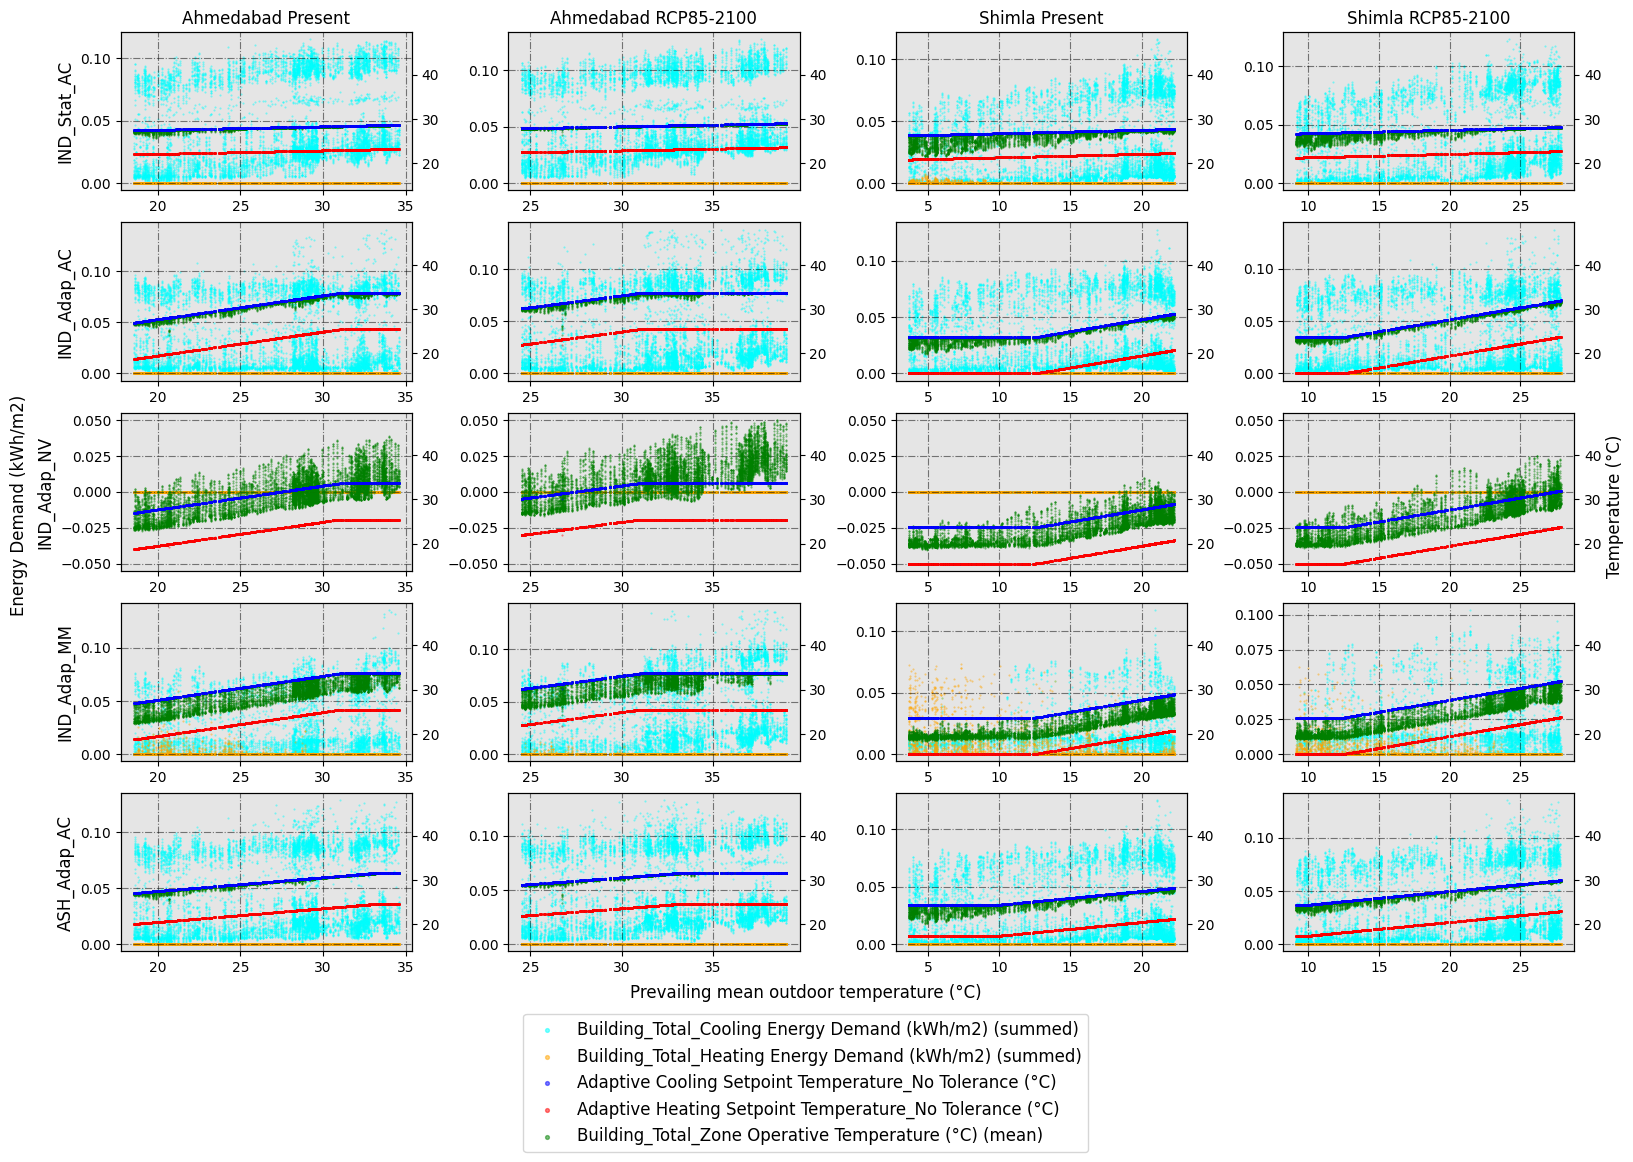

In [26]:
dataset_hourly.scatter_plot(
    vars_to_gather_rows=['ComfStand', 'ComfMod', 'HVACmode'],
    vars_to_gather_cols=['EPW_City_or_subcountry', 'EPW_Scenario-Year'],
    data_on_x_axis='Block1:PerimeterXZNX4_ASHRAE 55 Running mean outdoor temperature (°C)',
    data_on_y_main_axis=[
        [
            'Energy Demand (kWh/m2)',
            [
                'Building_Total_Cooling Energy Demand (kWh/m2) (summed)',
                'Building_Total_Heating Energy Demand (kWh/m2) (summed)',
            ]
        ],
    ],
    data_on_y_sec_axis=[
        [
            'Temperature (°C)',
            [
                'Adaptive Cooling Setpoint Temperature_No Tolerance (°C)',
                'Adaptive Heating Setpoint Temperature_No Tolerance (°C)',
                'Building_Total_Zone Operative Temperature (°C) (mean)'
            ]
        ],
    ],
    colorlist_y_main_axis=[
        [
            'Energy Demand (kWh/m2)',
            [
                'cyan',
                'orange',
            ]
        ],
    ],
    colorlist_y_sec_axis=[
        [
            'Temperature (°C)',
            [
                'blue',
                'red',
                'green'
            ]
        ],
    ],
    #best_fit_deg_y_main_axis=[
        #[
            #'Energy Demand (kWh/m2)',
            #[
                #1,
                #1,
            #]
        #],
    #],
    cols_renaming_dict={
        'Ahmedabad[Present': 'Ahmedabad Present',
        'Ahmedabad[RCP85-2100': 'Ahmedabad RCP85-2100',
        'Shimla[Present': 'Shimla Present',
        'Shimla[RCP85-2100': 'Shimla RCP85-2100'
    },
    rows_renaming_dict={
        'CS_IND IMAC C NV[CM_0[HM_0': 'IND_Stat_AC',
        'CS_IND IMAC C NV[CM_3[HM_0': 'IND_Adap_AC',
        'CS_IND IMAC C NV[CM_3[HM_1': 'IND_Adap_NV',
        'CS_IND IMAC C NV[CM_3[HM_2': 'IND_Adap_MM',
        'CS_INT ASHRAE55[CM_3[HM_0': 'ASH_Adap_AC'
    },
    sharex=False,
    sharey=False,
    supxlabel='Prevailing mean outdoor temperature (°C)',
    figname='testing_scatterplot_case_study',
    figsize=4,
    ratio_height_to_width=0.5,
    dpi=300,
    confirm_graph=True
)

Using a similar code snippet but changing method to ``time_plot`` and omitting the argument ``data_on_x_axis``, a figure with time on the x-axis can be generated. In this case, the argument ``sharex`` is also omitted, since the simulation period is the same for all cases.

The number of rows and the list of these is going to be:
No. of rows = 5
List of rows:
CS_IND IMAC C NV[CM_0[HM_0
CS_IND IMAC C NV[CM_3[HM_0
CS_IND IMAC C NV[CM_3[HM_1
CS_IND IMAC C NV[CM_3[HM_2
CS_INT ASHRAE55[CM_3[HM_0
The renamed rows are going to be:
IND_Stat_AC
IND_Adap_AC
IND_Adap_NV
IND_Adap_MM
ASH_Adap_AC
The number of columns and the list of these is going to be:
No. of columns = 4
List of columns:
Ahmedabad[Present
Ahmedabad[RCP85-2100
Shimla[Present
Shimla[RCP85-2100
The renamed columns are going to be:
Ahmedabad Present
Ahmedabad RCP85-2100
Shimla Present
Shimla RCP85-2100


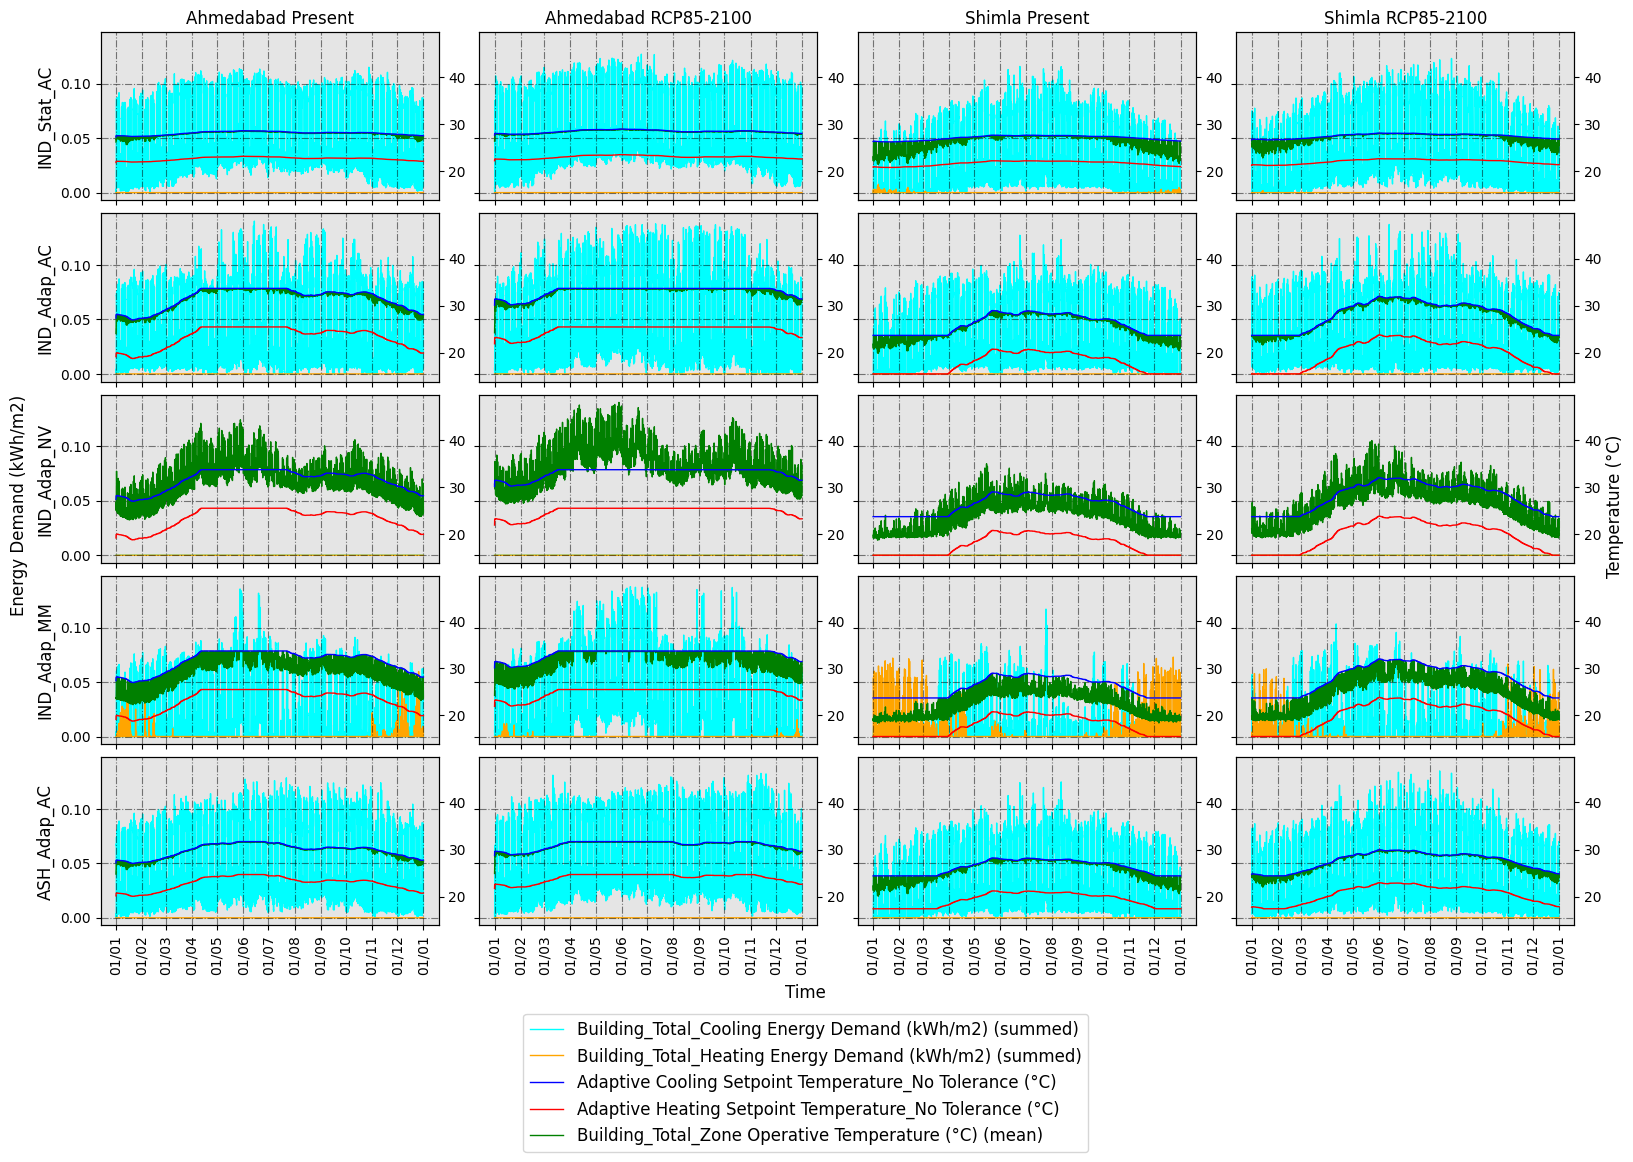

In [27]:
dataset_hourly.time_plot(
    vars_to_gather_rows=['ComfStand', 'ComfMod', 'HVACmode'],
    vars_to_gather_cols=['EPW_City_or_subcountry', 'EPW_Scenario-Year'],
    data_on_y_main_axis=[
        [
            'Energy Demand (kWh/m2)',
            [
                'Building_Total_Cooling Energy Demand (kWh/m2) (summed)',
                'Building_Total_Heating Energy Demand (kWh/m2) (summed)',
            ]
        ],
    ],
    data_on_y_sec_axis=[
        [
            'Temperature (°C)',
            [
                'Adaptive Cooling Setpoint Temperature_No Tolerance (°C)',
                'Adaptive Heating Setpoint Temperature_No Tolerance (°C)',
                'Building_Total_Zone Operative Temperature (°C) (mean)'
            ]
        ],
    ],
    colorlist_y_main_axis=[
        [
            'Energy Demand (kWh/m2)',
            [
                'cyan',
                'orange',
            ]
        ],
    ],
    colorlist_y_sec_axis=[
        [
            'Temperature (°C)',
            [
                'blue',
                'red',
                'green'
            ]
        ],
    ],
    cols_renaming_dict={
        'Ahmedabad[Present': 'Ahmedabad Present',
        'Ahmedabad[RCP85-2100': 'Ahmedabad RCP85-2100',
        'Shimla[Present': 'Shimla Present',
        'Shimla[RCP85-2100': 'Shimla RCP85-2100'
    },
    rows_renaming_dict={
        'CS_IND IMAC C NV[CM_0[HM_0': 'IND_Stat_AC',
        'CS_IND IMAC C NV[CM_3[HM_0': 'IND_Adap_AC',
        'CS_IND IMAC C NV[CM_3[HM_1': 'IND_Adap_NV',
        'CS_IND IMAC C NV[CM_3[HM_2': 'IND_Adap_MM',
        'CS_INT ASHRAE55[CM_3[HM_0': 'ASH_Adap_AC'
    },
    sharey=True,
    figname='testing_timeplot_case_study',
    figsize=4,
    ratio_height_to_width=0.5,
    dpi=300,
    confirm_graph=True
)

Finally, using ``scatter_plot_with_baseline`` a different scatter plot can be generated. In this case, it is mainly used to compare some combination of variables gathered in columns with the remaining variants. In the example below, the total heating and cooling energy demands will be compared using the combination ``'CS_IND IMAC C NV[CM_3[HM_2'`` (or IND_Adap_MM) as the baseline, since it is expected to provide the greater energy savings. The same ``Table`` instance will be used, however, to avoid plotting an empty figure, since energy demand is null in the combination ``'CS_IND IMAC C NV[CM_3[HM_1'`` (or IND_Adap_NV), since it is on naturally ventilated mode, the argument ``detailed_cols`` is used. In this argument, all the combinations to be plotted are specified, that is, all of them except the NV and the baseline.

The number of rows and the list of these is going to be:
No. of rows = 4
List of rows:
Ahmedabad[Present
Ahmedabad[RCP85-2100
Shimla[Present
Shimla[RCP85-2100
The renamed rows are going to be:
Ahmedabad Present
Ahmedabad RCP85-2100
Shimla Present
Shimla RCP85-2100
The number of columns and the list of these is going to be:
No. of columns = 3
List of columns:
CS_IND IMAC C NV[CM_0[HM_0
CS_IND IMAC C NV[CM_3[HM_0
CS_INT ASHRAE55[CM_3[HM_0
The renamed columns are going to be:
IND_Stat_AC
IND_Adap_AC
ASH_Adap_AC


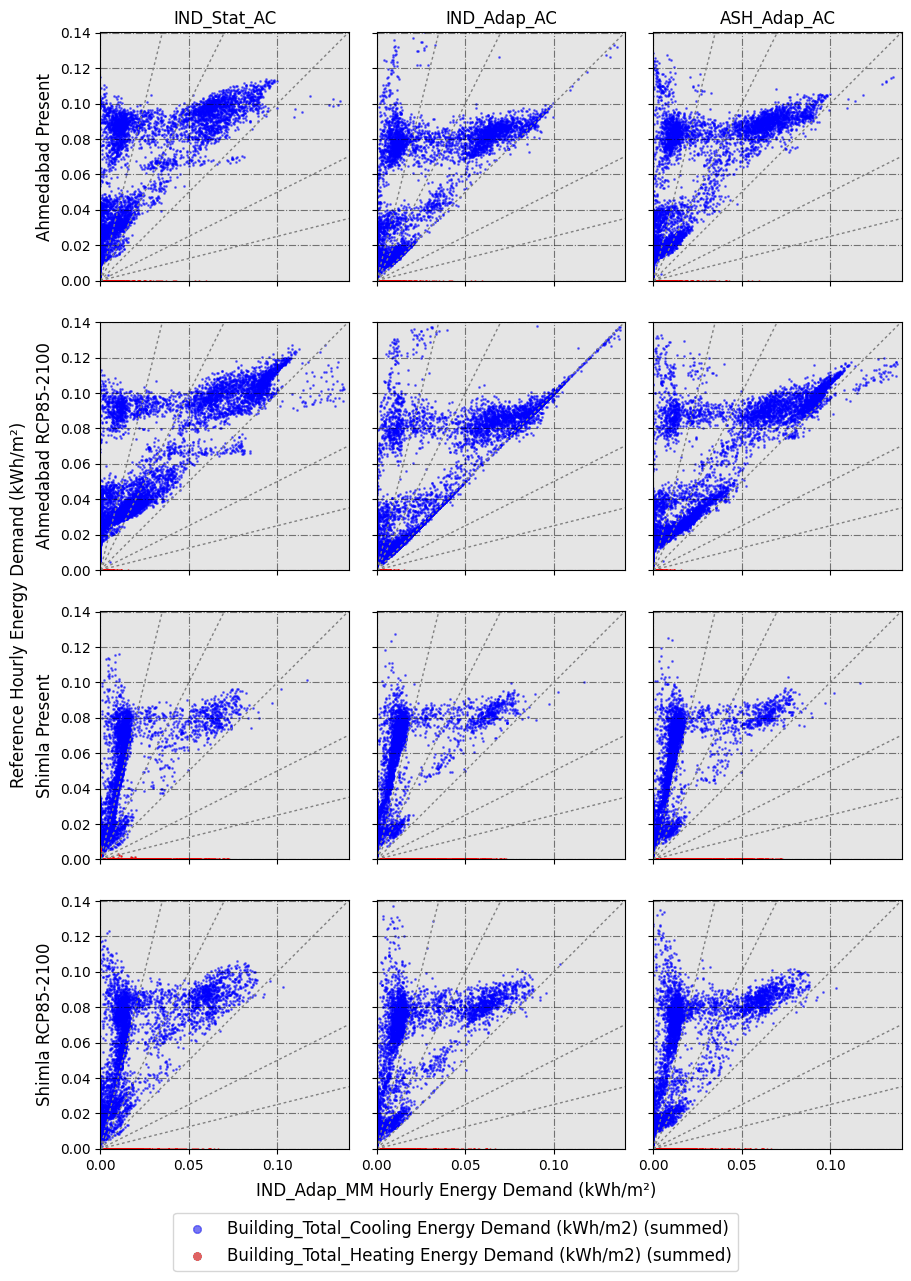

In [28]:
dataset_hourly.scatter_plot_with_baseline(
    vars_to_gather_rows=['EPW_City_or_subcountry', 'EPW_Scenario-Year'],
    vars_to_gather_cols=['ComfStand', 'ComfMod', 'HVACmode'],
    detailed_cols=[
        'CS_IND IMAC C NV[CM_0[HM_0',
        'CS_IND IMAC C NV[CM_3[HM_0',
        'CS_INT ASHRAE55[CM_3[HM_0'
    ],
    data_on_y_axis_baseline_plot=[
                'Building_Total_Cooling Energy Demand (kWh/m2) (summed)',
                'Building_Total_Heating Energy Demand (kWh/m2) (summed)',
    ],
    colorlist_baseline_plot_data=[
                'blue',
                'red'
    ],
    baseline='CS_IND IMAC C NV[CM_3[HM_2',
    rows_renaming_dict={
        'Ahmedabad[Present': 'Ahmedabad Present',
        'Ahmedabad[RCP85-2100': 'Ahmedabad RCP85-2100',
        'Shimla[Present': 'Shimla Present',
        'Shimla[RCP85-2100': 'Shimla RCP85-2100'
    },
    cols_renaming_dict={
        'CS_IND IMAC C NV[CM_0[HM_0': 'IND_Stat_AC',
        'CS_IND IMAC C NV[CM_3[HM_0': 'IND_Adap_AC',
        'CS_INT ASHRAE55[CM_3[HM_0': 'ASH_Adap_AC'
    },
    supxlabel='IND_Adap_MM Hourly Energy Demand (kWh/m²)',
    supylabel='Reference Hourly Energy Demand (kWh/m²)',
    figname='testing_scatterplotbaseline_case_study',
    figsize=3,
    dpi=300,
    confirm_graph=True
)

### 3.3.3 Saving the session

The CSV files of the simulations stay in the folder, but the instances of ``Table`` made above (``dataset_runperiod`` and ``dataset_hourly``) are lost when the notebook is closed or its kernel is restarted, and making them again reads all the CSV files, which takes a while when there are many simulations. To resume the analysis later without making them again, they can be saved in files:
- the method ``save`` of ``Table`` saves a table in a pickle file (``.pkl``), which ``Table.load`` reads to resume the session, and in a JSON file (``.json``), which can be read with any text editor: the arguments of the table, its zones, the variables whose values differ between the simulations and its rows;
- the function ``save_session`` of ``accim.utils`` saves several objects at once, also in a pickle file and a JSON file: in this case, both tables and the lists of files that the notebook uses, such as ``input_files``, which the cleanup at the end of the notebook needs.

In [29]:
dataset_runperiod.save('case_study_runperiod')

The table has been saved in case_study_runperiod.pkl (Table.load resumes it) and in case_study_runperiod.json (to read it).


('case_study_runperiod.pkl',
 'case_study_runperiod.json')

In [30]:
from accim.utils import save_session
save_session(
    'case_study_session',
    dataset_runperiod=dataset_runperiod,
    dataset_hourly=dataset_hourly,
    input_files=input_files,
    input_epws=input_epws,
    csvs=csvs,
)

The session has been saved in case_study_session.pkl (load_session resumes it) and in case_study_session.json (to read it).


('case_study_session.pkl',
 'case_study_session.json')

In a new session, for instance after restarting the kernel, the objects can be loaded instead of running the notebook again from the beginning: ``load_session`` returns them in a dictionary, by name, and ``Table.load`` returns the table. Their methods work as before saving them. Since pickle files can run code when they are read, open only those that you or someone you trust saved.

In [31]:
from accim.utils import load_session
session = load_session('case_study_session.pkl')
dataset_hourly = session['dataset_hourly']
input_files = session['input_files']

dataset_runperiod = Table.load('case_study_runperiod.pkl')
dataset_runperiod.wrangled_df_unstacked

The session saved on 2026-11-08 14:15:05 with accim 1.1.0 in . has been loaded from case_study_session.pkl: dataset_runperiod (Table), dataset_hourly (Table), input_files (list), input_epws (list), csvs (list).
The table has been loaded from case_study_runperiod.pkl: 16 rows and 21 columns, with the frequency runperiod.


EPW_City_or_subcountry                                                         Ahmedabad  \
EPW_Scenario                                                                     Present   
EPW_Year                                                                         Present   
Building_Total_Cooling Energy Demand (kWh/m2) (... Ind_Stat_AC                    421.76   
                                                   Ind_Adap_AC                    322.38   
                                                   Ind_Adap_MM                    150.37   
                                                   ASH_Adap_AC                    379.26   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)      0.64   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)      0.53   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)      0.60   
Building_Total_Heating Energy Demand (kWh/m2) (... Ind_Stat_AC                      0.00   
                                                   Ind_Adap_AC                      0.00   
                                                   Ind_Adap_MM                      2.74   
                                                   ASH_Adap_AC                      0.00   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)      -inf   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)      -inf   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)      -inf   
Building_Total_Total Energy Demand (kWh/m2) (su... Ind_Stat_AC                    421.76   
                                                   Ind_Adap_AC                    322.38   
                                                   Ind_Adap_MM                    153.11   
                                                   ASH_Adap_AC                    379.26   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)      0.64   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)      0.53   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)      0.60   

EPW_City_or_subcountry                                                                  \
EPW_Scenario                                                                     RCP85   
EPW_Year                                                                          2100   
Building_Total_Cooling Energy Demand (kWh/m2) (... Ind_Stat_AC                  487.70   
                                                   Ind_Adap_AC                  364.82   
                                                   Ind_Adap_MM                  252.19   
                                                   ASH_Adap_AC                  429.44   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)    0.48   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)    0.31   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)    0.41   
Building_Total_Heating Energy Demand (kWh/m2) (... Ind_Stat_AC                    0.00   
                                                   Ind_Adap_AC                    0.00   
                                                   Ind_Adap_MM                    0.29   
                                                   ASH_Adap_AC                    0.00   
                                                   1-(Ind_Adap_MM/Ind_Stat_AC)    -inf   
                                                   1-(Ind_Adap_MM/Ind_Adap_AC)    -inf   
                                                   1-(Ind_Adap_MM/ASH_Adap_AC)    -inf   
Building_Total_Total Energy Demand (kWh/m2) (su... Ind_Stat_AC                  487.70   
                                                   Ind_Adap_AC                  364.82   
                                                   Ind_Adap_MM                  2

The JSON files are a copy to read, for instance to check later how a table was made; they are not read back. These are the contents of the JSON file of ``dataset_runperiod``, and the variables whose values differ between its simulations:

In [32]:
import json
with open('case_study_runperiod.json', encoding='utf-8') as file:
    runperiod_json = json.load(file)
print(list(runperiod_json))
print(json.dumps(runperiod_json['suggested_vars_dict'], indent=2))

['description', 'accim_version', 'saved', 'folder', 'arguments', 'frequency', 'occupied_zone_list', 'hvac_zone_list', 'block_list', 'cols_for_multiindex', 'suggested_vars_dict', 'type_of_table', 'custom_cols', 'indexcols', 'val_cols', 'df', 'wrangled_df_unstacked']
{
  "ComfStand": [
    "CS_IND IMAC C NV",
    "CS_INT ASHRAE55"
  ],
  "ComfMod": [
    "CM_0",
    "CM_3"
  ],
  "HVACmode": [
    "HM_0",
    "HM_2"
  ],
  "EPW_City_or_subcountry": [
    "Ahmedabad",
    "Shimla"
  ],
  "EPW_Scenario-Year": [
    "Present",
    "RCP85-2100"
  ],
  "EPW_Scenario": [
    "Present",
    "RCP85"
  ],
  "EPW_Year": [
    "Present",
    "2100"
  ]
}


Finally, so that this jupyter notebook can be properly run again, all files different than the input ones will be deleted.

In [33]:
for i in input_epws:
    shutil.move(f'backup/{i}', i)
shutil.move('backup/SmallOffice.idf', 'SmallOffice.idf')

'SmallOffice.idf'

In [34]:
files_to_delete = [i for i in listdir() if i not in input_files]
print(*files_to_delete, sep='\n')

case_study_runperiod.json
case_study_runperiod.pkl
case_study_session.json
case_study_session.pkl
India_Ahmedabad_Present.epw
India_Ahmedabad_RCP85-2100.epw
India_Shimla_Present.epw
India_Shimla_RCP85-2100.epw
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X.idf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_Present.audit
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_Present.bnd
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_Present.csv
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_Present.dxf
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_Present.eio
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[India_Ahmedabad_Present.end
SmallOffice[CS_IND IMAC C NV[CA_80[CM_0[HM_0[VC_X[VO_X[MT_X[MW_X[AT_0.1[NS_X[

In [35]:
for i in files_to_delete:
    remove(i)